# Candidate A: gradual catch-up adjustment

This is **one fixed exploratory follow-up**, after the original IC research,
beta diagnostics and negative economic results. It is not fresh validation.
Keep your original audited strategy and report intact. Do not change parameters
after viewing outcomes or automatically substitute the better-looking strategy.

Install every file in this package into its matching location in your existing
sprint clone. All filenames are new; no original `janice_leadlag.py` is replaced.
Use your repository's `.venv` kernel and Restart Kernel / Run All.

**Run order:** create and record both A/B plans before the first new real-data
performance run. Run A first, then B once as recorded. Report every outcome and
stop after these two candidates. Bug-fix reruns must remain in the run history.
The notebooks have a plan-only default; they do not read real data in that mode.

**Verification:**13 synthetic tests passed; both reference books matched the original
timestamp-fixed controls. This notebook completed end-to-end on synthetic data,
including20 backtests and4 paired comparisons. Its plan-only path was checked.
Both strategy wrappers also ran successfully in isolated processes. Outputs are
cleared. No new real-market result or full official audit is claimed.


## Economic hypothesis
The original ungated catch-up portfolio changes too aggressively. Move only
25% toward its existing issued target at each 8h decision:

`new = 0.75 * previous + 0.25 * original_ungated_target`.

The target still includes the original score, .015 no-trade band and neutral
unit-gross construction. The NEW book has no additional band and **no rescale
back to gross1**. A zero target causes gradual decay. First entry is normally
gross .25, not1. Added inertia may erase the short-lived return advantage.

The main control is the same original ungated catch-up book. Inspect turnover,
gross PnL and net PnL together with average exposure. Losing less through taking
smaller positions is not sufficient evidence of better execution economics.


In [1]:
import sys
from pathlib import Path
ROOT=next((p for p in (Path.cwd(),*Path.cwd().parents)
           if (p/'src'/'backtest.py').is_file() and (p/'src'/'contrib'/'janice.py').is_file()),None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside your existing sprint clone.')
sys.path.insert(0,str(ROOT))
import pandas as pd
required=['src/contrib/janice_alternatives.py','research/track03_followup_runner.py',
          'strategies/janice_gradual_catchup.py','strategies/janice_slow_momentum.py',
          'tests/contrib/test_janice_alternatives.py']
absent=[p for p in required if not (ROOT/p).is_file()]
if absent:raise FileNotFoundError('Copy all package files first: '+str(absent))
from research.track03_followup_runner import plan_text,run_study,plot_study
from IPython.display import display
print('Interpreter:',sys.executable)
print('Repository:',ROOT)


Interpreter: /Users/janicejizhe/Desktop/quant sprint/open-quant-sprint/.venv/bin/python
Repository: /Users/janicejizhe/Desktop/quant sprint/open-quant-sprint


## 1. Fixed switches and pre-run plan
First run with RUN_EXPERIMENT=False. The next cell creates/prints a plan without
reading training data. Post BOTH plans in your PR/research log before enabling
either new performance run. Existing matching plans are reused; changed plans
raise an error so earlier choices are not silently overwritten.


In [2]:
CANDIDATE = 'A'
USE_REAL_DATA = True
RUN_EXPERIMENT = True
RUN_CORRECTNESS_TESTS = True
PLAN_PATH=ROOT/'research_plans'/f'janice_candidate_{CANDIDATE.lower()}.txt'
planned=plan_text(CANDIDATE)
PLAN_PATH.parent.mkdir(parents=True,exist_ok=True)
if PLAN_PATH.exists():
    if PLAN_PATH.read_text(encoding='utf-8')!=planned:
        raise ValueError('Existing plan differs: preserve it and document any new trial explicitly.')
else:
    with PLAN_PATH.open('x',encoding='utf-8') as f:f.write(planned)
print(planned)
print('Plan file:',PLAN_PATH)


FIXED EXPLORATORY FOLLOW-UP PLAN — CANDIDATE A

Record this in your PR BEFORE the new real-data performance run. Previous IC,
beta diagnostics and economic results have already been examined. A local
plan file is not evidence that it was posted. Keep the original audited
strategy unchanged. Run each candidate once as planned, disclose any bug-fix
reruns, and report every cost/delay outcome. No search over windows, signs,
fractions, clock phases or cutoffs. A post-hoc historical split is not fresh
validation. Do not tune on the sprint holdout or forward periods.

Success is not merely losing less through lower exposure. Inspect gross/net
PnL, fees, turnover per unit exposure, delay sensitivity and uncertainty.
Candidate A additionally has a descriptive, EX-POST constant-scaled reference
matching its average gross. This uses realized future exposures, is NOT a
prospective strategy, has no inferential CI and is never audited/submitted.
It is not volatility/risk matching. Cash (zero modele

## 2. Correctness tests (synthetic only)
The tests include exact partial-adjustment identity, no gross re-normalization,
daily decision timing, momentum against an independent numerical reference,
volume/flow independence for B, final neutrality/exposure, original-index
alignment, timestamp resolution, genuine gap rejection, prefix/future causality,
preserved post-warm-up PnL and linear exposure-control accounting.
A failed check stops execution. The test suite never evaluates real performance.


In [3]:
if RUN_CORRECTNESS_TESTS:
    import os,subprocess
    env=dict(os.environ)
    env['PYTHONPATH']=str(ROOT)+(os.pathsep+env['PYTHONPATH'] if env.get('PYTHONPATH') else '')
    tests=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests/contrib',
        '-p','test_janice_alternatives.py','-v'],cwd=ROOT,env=env,capture_output=True,text=True)
    print(tests.stdout+tests.stderr)
    if tests.returncode:raise RuntimeError('Correctness tests failed; do not interpret new results.')


test_a_first_position_is_quarter_target_not_full_gross (test_janice_alternatives.FixedAlternativeTests.test_a_first_position_is_quarter_target_not_full_gross) ... ok
test_a_full_constraints_causality_and_determinism (test_janice_alternatives.FixedAlternativeTests.test_a_full_constraints_causality_and_determinism) ... ok
test_a_matches_fixed_convex_rule_at_every_decision (test_janice_alternatives.FixedAlternativeTests.test_a_matches_fixed_convex_rule_at_every_decision) ... ok
test_b_changes_only_at_fixed_daily_decisions (test_janice_alternatives.FixedAlternativeTests.test_b_changes_only_at_fixed_daily_decisions) ... ok
test_b_first_decision_matches_independent_window_calculation (test_janice_alternatives.FixedAlternativeTests.test_b_first_decision_matches_independent_window_calculation) ... ok
test_b_full_constraints_causality_and_determinism (test_janice_alternatives.FixedAlternativeTests.test_b_full_constraints_causality_and_determinism) ... ok
test_b_is_independent_of_flow_and_volume

## 3. Execute the one planned candidate
Set RUN_EXPERIMENT=True only after recording the plans. Keep USE_REAL_DATA=True
to read the existing `data/train_1h.parquet`. False runs synthetic plumbing only.

The runner checks final weights, prefix invariance, changed futures and repeated
calls, then runs20 fixed backtests: candidate/reference × default/extra-hour
delay × 0/3/5/10bps/tiered costs. Funding is included even at0bps. Features and
liquidity tiers retain full prior history; reporting starts after720 hours for
both books. No data are downloaded and no holdout/forward file is used.


In [4]:
result=None
if RUN_EXPERIMENT:
    result=run_study(ROOT,CANDIDATE,PLAN_PATH,synthetic=not USE_REAL_DATA)
    print('Saved:',result['out'])
    print('Weight checks:',result['metadata']['checks'])
    print('Reporting hours:',result['metadata']['n_evaluation_hours'])
else:
    print('Plan-only mode. Record both plans, then set RUN_EXPERIMENT=True and restart/run all.')


Saved: /Users/janicejizhe/Desktop/quant sprint/open-quant-sprint/results/track03_candidate_a_real_20261119T023821Z_125a9a
Weight checks: final-weight constraints,3 prefix cuts,future perturbation,determinism passed
Reporting hours: 14151


## 4. Primary result: 5bps plus one real hour of execution delay
`lag_bars=1` enters at the signal close and earns the next close-to-close return.
`lag_bars=2` adds one real hour; this is the primary execution test. Compare all
rows, but do not choose a cheaper fee or faster fill after viewing the result.

Cumulative PnL and drawdown are additive fixed-notional quantities, not compounded
account returns. Margin depletion, liquidation, spread, impact and uncertain fills
are absent. Sharpe intervals use the repository's existing bootstrap routine.


In [5]:
if result is not None:
    primary=result['summary'].xs((2,'5bps'),level=('lag_bars','cost'))
    display(primary[['sharpe','sharpe_ci_low','sharpe_ci_high','cumulative_net_pnl',
        'gross_price_pnl','fee_cost','funding_cost','average_gross','active_hour_fraction',
        'annualized_volatility','turnover_per_day','turnover_per_day_per_average_gross']].round(6))


,sharpe,sharpe_ci_low,sharpe_ci_high,cumulative_net_pnl,gross_price_pnl,fee_cost,funding_cost,average_gross,active_hour_fraction,annualized_volatility,turnover_per_day,turnover_per_day_per_average_gross
portfolio,,,,,,,,,,,,
reference,-2.959,-4.45,-1.41,-1.0654,0.1580,1.2455,-0.0221,0.999859,0.999859,0.222854,4.224710,4.225307
candidate,-1.545,-2.88,-0.11,-0.2160,0.0091,0.2362,-0.0111,0.378798,0.999859,0.086560,0.801356,2.115522


## 5. All cost/delay outcomes, return paths and break-even fee
Funding cost can be negative (a receipt). Break-even fees are NaN when no
nonnegative fee breaks even or turnover is zero. A smoother/slower strategy
does not succeed merely because fees are lower: gross performance must remain.


sharpe  cumulative_net_pnl  fee_cost  \
portfolio lag_bars cost                                           
reference 1        0bps     1.542              0.5603    0.0000   
                   3bps    -0.515             -0.1870    0.7473   
                   5bps    -1.884             -0.6852    1.2455   
                   10bps   -5.252             -1.9307    2.4910   
                   tiered  -3.943             -1.4422    2.0025   
          2        0bps     0.502              0.1801    0.0000   
                   3bps    -1.580             -0.5672    0.7473   
                   5bps    -2.959             -1.0654    1.2455   
                   10bps   -6.331             -2.3109    2.4910   
                   tiered  -5.025             -1.8223    2.0025   
candidate 1        0bps     0.932              0.1317    0.0000   
                   3bps    -0.071             -0.0100    0.1417   
                   5bps    -0.739             -0.1045    0.2362   
                   10bps   -2.406             -0.3408    0.4725   
                   tiered  -1.753             -0.2480    0.3798   
          2        0bps     0.145              0.0202    0.0000   
                   3bps    -0.870             -0.1215    0.1417   
                   5bps    -1.545             -0.2160    0.2362   
                   10bps   -3.223             -0.4523    0.4725   
                   tiered  -2.566             -0.3596    0.3798   

                           average_gross  turnover_per_day  
portfolio lag_bars cost                                     
reference 1        0bps         0.999929          4.224710  
                   3bps         0.999929          4.224710  
                   5bps         0.999929          4.224710  
                   10bps        0.999929          4.224710  
                   tiered       0.999929          4.224710  
          2        0bps         0.999859          4.224710  
                   3bps         0.999859          4.224710  
                   5bps         0.999859          4.224710  
                   10bps        0.999859          4.224710  
                   tiered       0.999859          4.224710  
candidate 1        0bps         0.378821          0.801356  
                   3bps         0.378821          0.801356  
                   5bps         0.378821          0.801356  
                   10bps        0.378821          0.801356  
                   tiered       0.378821          0.801356  
          2        0bps         0.378798          0.801356  
                   3bps         0.378798          0.801356  
                   5bps         0.378798          0.801356  
                   10bps        0.378798          0.801356  
                   tiered       0.378798          0.801356

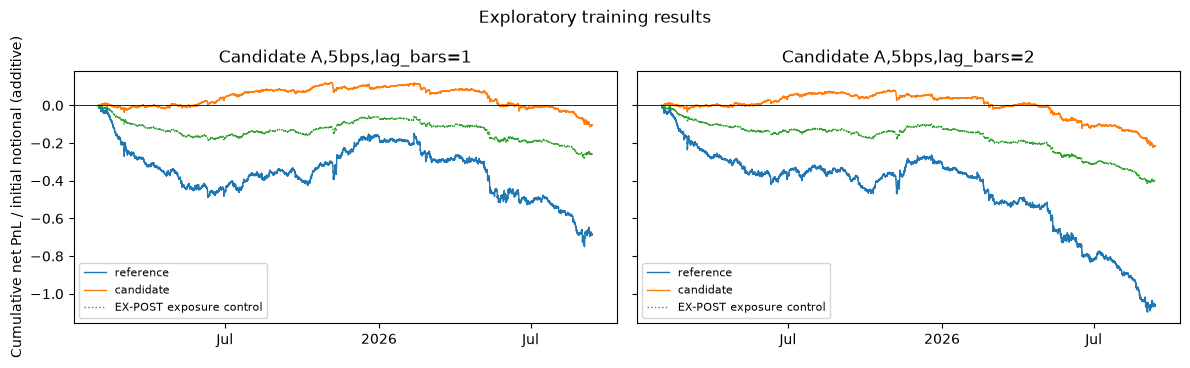

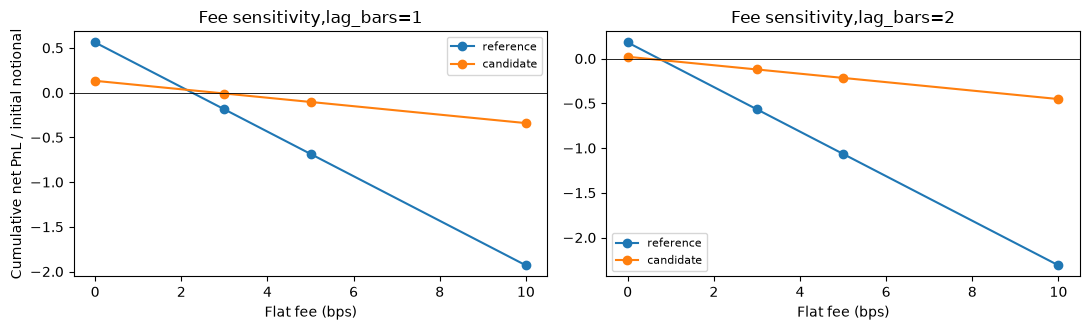

,portfolio,lag_bars,breakeven_fee_bps,note
0,reference,1,2.24925,Linear fee-only estimate; funding included; no...
1,reference,2,0.72317,Linear fee-only estimate; funding included; no...
2,candidate,1,2.78830,Linear fee-only estimate; funding included; no...
3,candidate,2,0.42833,Linear fee-only estimate; funding included; no...


In [6]:
if result is not None:
    with pd.option_context('display.max_rows',25):
        display(result['summary'][['sharpe','cumulative_net_pnl','fee_cost','average_gross',
            'turnover_per_day']].round(6))
    plot_study(result,CANDIDATE,synthetic=not USE_REAL_DATA)
    display(result['breakeven'].round(5))


## 6. Paired results and stability
These are differences in **mean net PnL**, annualized linearly, not differences
in Sharpe or compounded growth. Candidate minus cash tests the modeled zero-PnL
cash reference (no collateral yield). An improvement over a losing reference
does not establish profitability. Weekly-block intervals are approximate,
pointwise and exploratory, not adjusted for multiple comparisons/prior research.
Quarterly rows are descriptive and first/last quarters may be partial.


In [7]:
if result is not None:
    display(result['pairs'].round(6))
    display(result['quarters'].round(6))


,lag_bars,comparison,mean_hourly_difference,annualized_mean_difference,annualized_ci_low,annualized_ci_high
0,1,candidate minus reference,0.000041,0.359480,0.059770,0.646458
1,1,candidate minus cash,-0.000007,-0.064691,-0.191897,0.063590
2,2,candidate minus reference,0.000060,0.525776,0.269199,0.801139
3,2,candidate minus cash,-0.000015,-0.133719,-0.258078,-0.013971


,reference,candidate
2025Q1,-0.279658,-0.000495
2025Q2,-0.090110,0.045597
2025Q3,-0.078449,-0.004381
2025Q4,0.137549,-0.005530
2026Q1,-0.209743,-0.032370
2026Q2,-0.301292,-0.114134
2026Q3,-0.243653,-0.104699


## 7. Exposure diagnostic: did we simply take smaller positions?
The dotted curve and table scale the reference to the candidate's realized
average gross. This is **EX POST**: it uses the full evaluation period's
exposures. It is not a causal strategy, not risk/volatility matching and
never a submission/audit candidate. No CI is reported for this descriptive
comparison. Do not use this scaling coefficient in a trading function.

If A loses less but performs similarly to this smaller-exposure reference,
lower exposure may explain much of the apparent improvement. Also compare
turnover per unit average gross and whether zero-fee PnL survived the lag.


In [8]:
if result is not None:
    display(result['control'].round(6))


,lag_bars,expost_scaling_factor,candidate_average_gross,candidate_net_pnl,descriptive_scaled_reference_net_pnl,warning
0,1,0.378848,0.378821,-0.1045,-0.259591,EX-POST mean-exposure comparison only; not pro...
1,2,0.378852,0.378798,-0.2160,-0.403612,EX-POST mean-exposure comparison only; not pro...


## 8. Finish and stop the trial
Save the output folder and report the entire experiment, including failure.
Examine5bps/extra-hour performance, tiered costs, uncertainty, turnover/exposure,
concentration in a short period and the full-panel audit reference CSV. A
positive training estimate is not independent evidence of an edge.

Keep your original Track03 PR intact. Do not automatically replace it with a
better-looking alternative. Discuss CandidateA as a track extension and CandidateB
as a separate hypothesis; the sprint limits out-of-track extra strategy PRs.
No additional window, sign, fraction or phase search is included.


If you proceed to formal review, run from the repository root:
```bash
.venv/bin/python -m pytest -q
.venv/bin/python -m src.audit strategies/janice_gradual_catchup.py --seed 20261116 --n-random-cuts 60 --log results/janice_candidate_a_audit.jsonl
```
These notebooks do not run or claim the full audit. Genuine causality/crash
failures require correction; a performance REJECT remains an acceptable outcome.
Code corrections are recorded reruns, not permission to retune the hypothesis.
